# **Exercice 1 :**

1. Lire l’image et l’afficher. Définir le filtre moyenneur H ci-dessous.

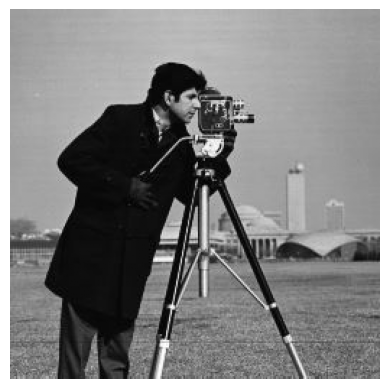

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Charger l'image cameraman intégrée dans skimage
image = cv2.imread("/content/drive/MyDrive/Traitement d'images/cameraman.jpg", cv2.IMREAD_GRAYSCALE)
# Afficher l'image en niveaux de gris
plt.imshow(image, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

In [ ]:
filtre_h = np.ones((3,3)) / 9
print(filtre_h)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


2. Appliquer H à I avec imfilter sous MATLAB ou cv2.filter2D sous Python.

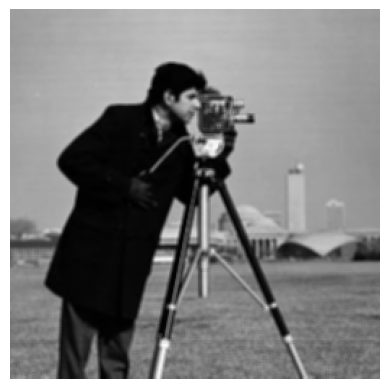

In [ ]:


image_filtree = cv2.filter2D(image, -1, filtre_h, borderType=cv2.BORDER_REPLICATE) #Le paramètre -1 indique que l'image filtrée aura la même profondeur/type que l'image d'origine

plt.imshow(image_filtree, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

3. Afficher côte à côte l’image originale et l’image filtrée.

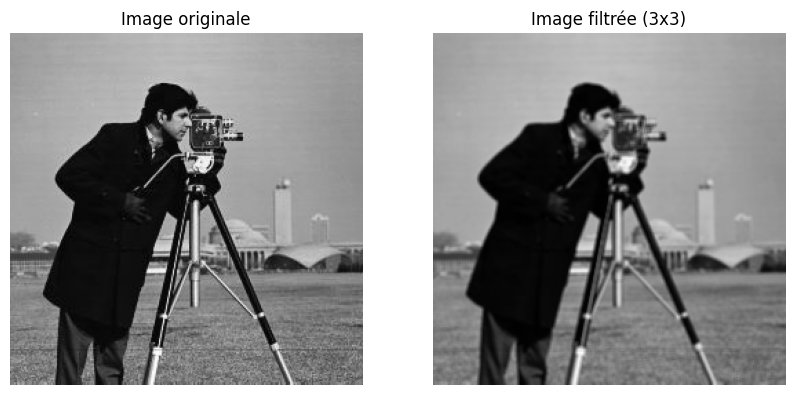

In [ ]:
plt.figure(figsize=(10, 5))

# Image originale
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Image originale")
plt.axis("off")

# Image filtrée
plt.subplot(1, 2, 2)
plt.imshow(image_filtree, cmap="gray")
plt.title("Image filtrée (3x3)")
plt.axis("off")

plt.show()

4. Que deviennent les détails et les contours ?

On voit que les contours sont moins définis, l'image est floutée

5. Augmenter la taille du filtre à 9 × 9, puis à 11 × 11. Définir des noyaux moyenneurs dont les coefficients
valent respectivement 1/81 et 1/121. Appliquer chaque filtre à l’image originale I.

6. Afficher et comparer les résultats des filtres 3 × 3, 9 × 9 et 11 × 11. Qu’observez-vous après augmentation de
la taille du filtre ?

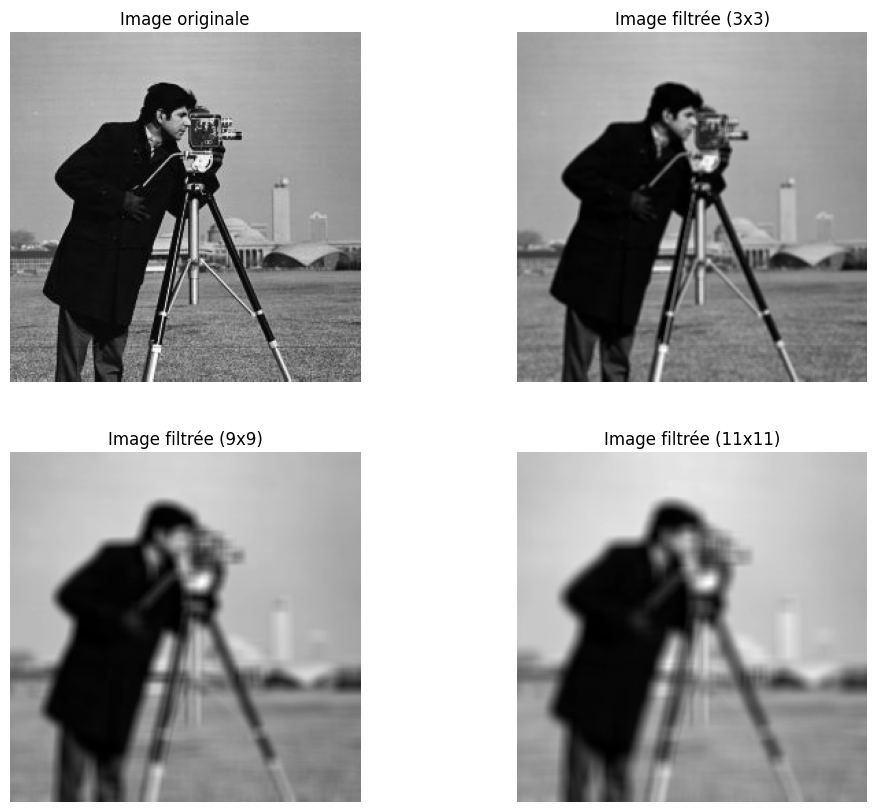

In [ ]:
filtre_h_9 = np.ones((9,9)) / 81
filtre_h_11 = np.ones((11,11)) / 121

image_filtree_9 = cv2.filter2D(image, -1, filtre_h_9, borderType=cv2.BORDER_REPLICATE)
image_filtree_11 = cv2.filter2D(image, -1, filtre_h_11, borderType=cv2.BORDER_REPLICATE)

plt.figure(figsize=(12, 10))

# Image originale
plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Image originale")
plt.axis("off")

# Image filtrée
plt.subplot(2, 2, 2)
plt.imshow(image_filtree, cmap="gray")
plt.title("Image filtrée (3x3)")
plt.axis("off")

# Image filtrée
plt.subplot(2, 2, 3)
plt.imshow(image_filtree_9, cmap="gray")
plt.title("Image filtrée (9x9)")
plt.axis("off")

# Image filtrée
plt.subplot(2, 2, 4)
plt.imshow(image_filtree_11, cmap="gray")
plt.title("Image filtrée (11x11)")
plt.axis("off")

plt.show()

On observe que plus la taille du filtre augmente, plus flou sera la photo

# **Exercice 2:**

1. Ajouter un bruit « sel et poivre » à I pour obtenir une image bruitée Ib (densité 0,05).

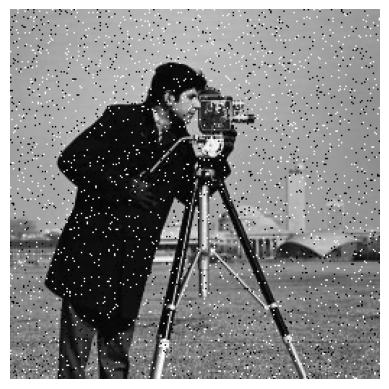

In [ ]:
from skimage.util import random_noise
#from google.colab.patches import cv2_imshow

#Ib = image_poivre_sel (=bruitée)
Ib = random_noise(image, mode='s&p', amount=0.05)

plt.imshow(Ib, cmap="gray")
plt.axis('off')  # Masquer les axes
plt.show()

#ATTENTION A PAS CHARGER L'IMAGE EN FLOAT SINON IL Y A DU BLANC PARTOUT!!!

2. Appliquer séparément un filtre moyenneur 3 × 3 et un filtre médian 3 × 3 à Ib.

3. Afficher l’original, l’image bruitée et les deux images filtrées.

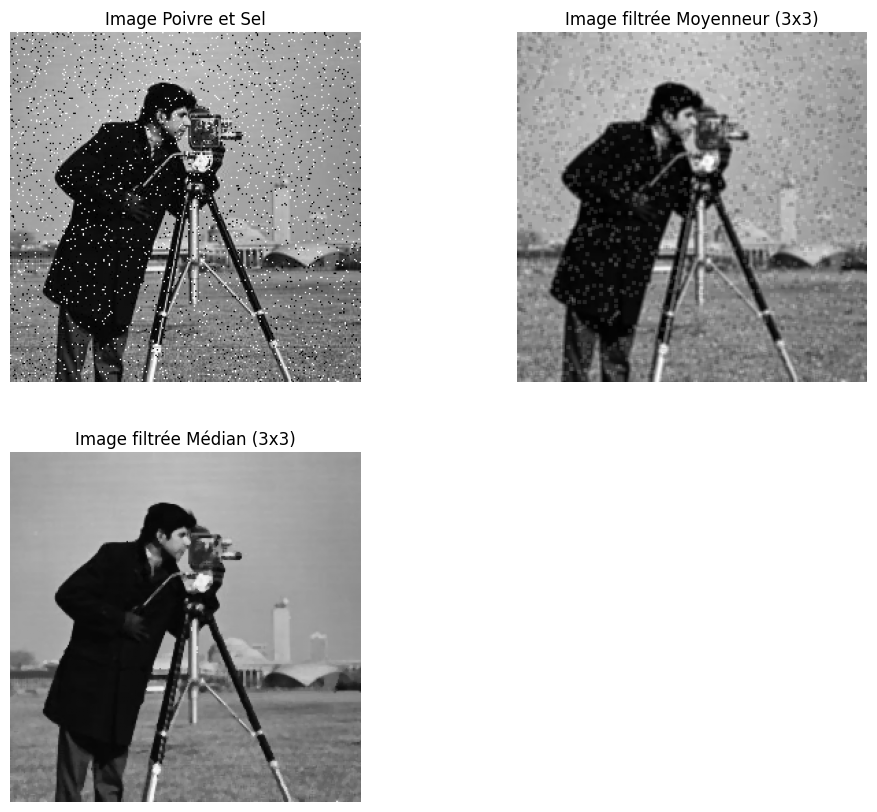

In [ ]:
from scipy import ndimage

image_moyenneur = cv2.filter2D(Ib, -1, filtre_h, borderType=cv2.BORDER_REPLICATE)
image_median = ndimage.median_filter(Ib, size=3)

plt.figure(figsize=(12, 10))

# Image Poivre et Sel
plt.subplot(2, 2, 1)
plt.imshow(Ib, cmap="gray")
plt.title("Image Poivre et Sel")
plt.axis("off")

# Image filtrée Moyenneur
plt.subplot(2, 2, 2)
plt.imshow(image_moyenneur, cmap="gray")
plt.title("Image filtrée Moyenneur (3x3)")
plt.axis("off")

# Image filtrée Médian
plt.subplot(2, 2, 3)
plt.imshow(image_median, cmap="gray")
plt.title("Image filtrée Médian (3x3)")
plt.axis("off")


plt.show()

4. Quel filtre élimine le mieux ce bruit tout en conservant les contours ?

Le filtre médian est bien plus efficace pour enlever le bruit poivre et sel.

# **Exercice 3:**

Détecter les contours d’une image et comparer deux méthodes.
1. Reprendre l’image originale I en niveaux de gris.

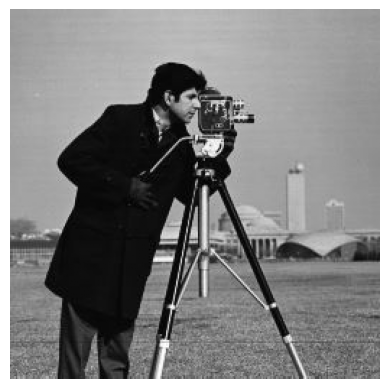

In [ ]:
# Afficher l'image en niveaux de gris
plt.imshow(image, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

2. Appliquer Sobel dans les deux directions et obtenir la norme du gradient avec la fonction prédéfinie.

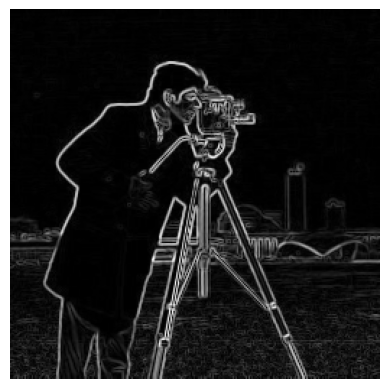

In [ ]:
from skimage import filters

image_sobel = filters.sobel(image)

plt.imshow(image_sobel, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

3. Faire de même avec Prewitt sur la même image.

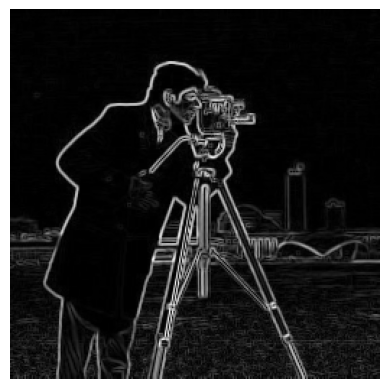

In [ ]:
image_prewitt = filters.prewitt(image)

plt.imshow(image_prewitt, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

4. Afficher côte à côte l’original, le résultat de Sobel et celui de Prewitt.

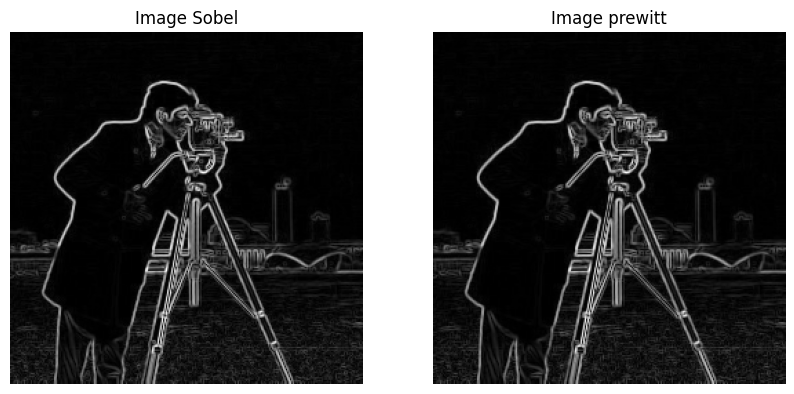

In [ ]:
plt.figure(figsize=(10, 5))

# Image Sobel
plt.subplot(1, 2, 1)
plt.imshow(image_sobel, cmap="gray")
plt.title("Image Sobel")
plt.axis("off")

# Image Prewitt
plt.subplot(1, 2, 2)
plt.imshow(image_prewitt, cmap="gray")
plt.title("Image prewitt")
plt.axis("off")

plt.show()

Sobel : poids double (² dans les formules) donc plus contrasté : plus le contour est évident plus il va l'accentuer.

# **Exercice 4 :**

Détecter les contours avec Canny et comparer le résultat à Sobel.
1. Reprendre l’image originale I en niveaux de gris.

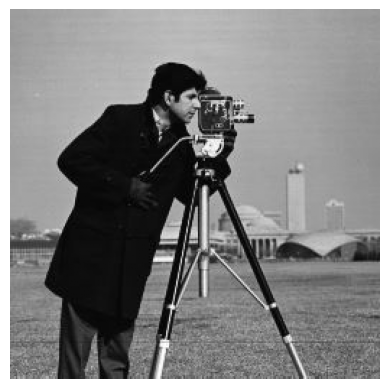

In [ ]:
# Afficher l'image en niveaux de gris
plt.imshow(image, cmap='gray')
plt.axis('off')  # Masquer les axes
plt.show()

2. Appliquer Canny avec les paramètres par défaut.

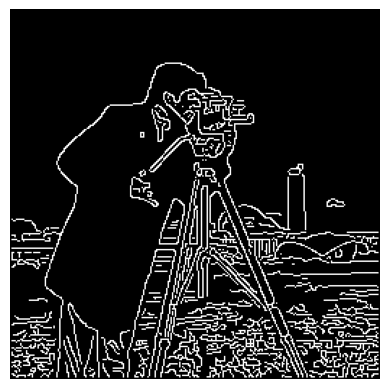

In [ ]:
from skimage import feature

image_canny = feature.canny(image)

plt.imshow(image_canny, cmap="gray")
plt.axis("off")
plt.show()

3. Afficher côte à côte l’original, le résultat de Sobel et celui de Canny.

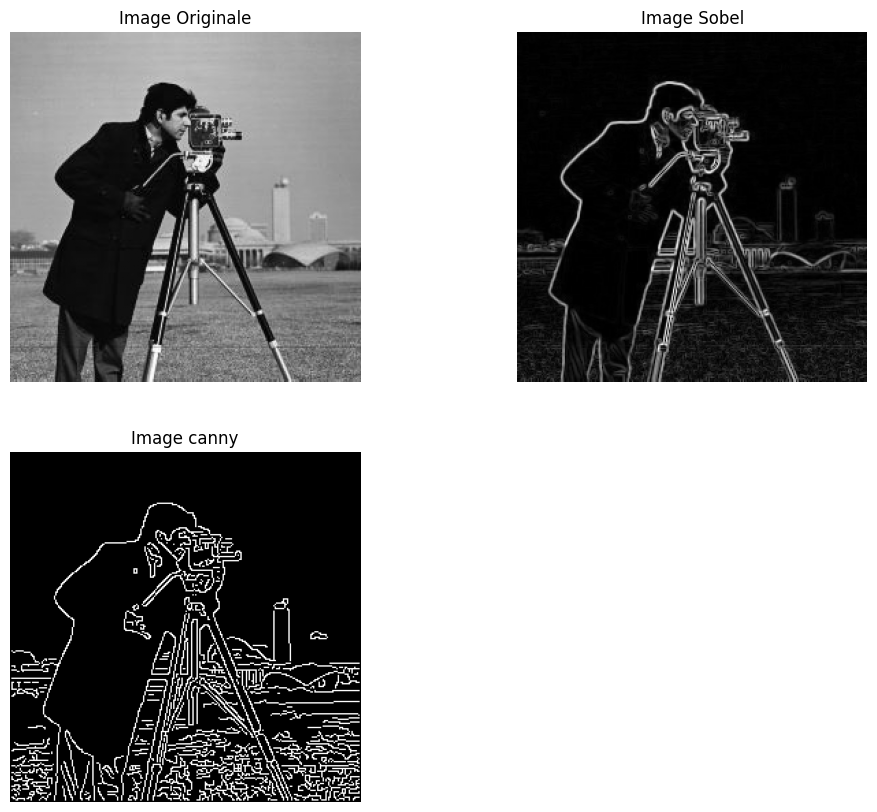

In [ ]:
plt.figure(figsize=(12, 10))

# Image Originale
plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Image Originale")
plt.axis("off")

# Image Sobel
plt.subplot(2, 2, 2)
plt.imshow(image_sobel, cmap="gray")
plt.title("Image Sobel")
plt.axis("off")

# Image Canny
plt.subplot(2, 2, 3)
plt.imshow(image_canny, cmap="gray")
plt.title("Image canny")
plt.axis("off")


plt.show()

4. Avec quelle méthode les contours semblent-ils les plus fins et les plus continus ?

Dans les deux langages, Canny renvoie une carte binaire : contours blancs sur fond noir. Sobel fournit ici une
intensité de gradient ; tenir compte de cette différence dans la comparaison.

C'est le détecteur de Canny qui offre les contours les plus fins (d'une largeur d'un seul pixel) et les plus continus.   

**(Pourquoi cette différence ?) :**

- Canny intègre une étape de suppression des non-maxima locaux (ce qui affine les contours à un pixel d'épaisseur) et un seuillage par hystérésis (qui connecte les segments pour former des contours continus). De plus, il renvoie une carte binaire.   

- Sobel calcule uniquement une intensité de gradient : les contours apparaissent plus flous, plus épais et varient en niveau de gris selon la force du contraste.